# 04 · Term weighting: TF and TF-IDF

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-nlp-course/blob/main/notebooks/04_tf_and_tfidf.ipynb)

*Practical NLP — a hands-on course in classical natural language processing · Notebook 4 of 12*

In notebook 03 we saw that raw Bag-of-Words counts reward words for being **frequent**, not for being
**informative**: *would*, *get* and *one* ranked near the top of every topic. **TF-IDF** fixes this by
multiplying how often a word occurs in a document (*term frequency*) by how rare it is across the corpus
(*inverse document frequency*). We will compute every number **by hand, from first principles**, and then
check that scikit-learn's `TfidfVectorizer` gives exactly the same matrix.

### Learning objectives
By the end of this notebook you will be able to:
1. Define and compute term frequency (raw, relative and log-scaled) by hand.
2. Define document frequency and inverse document frequency, and explain the intuition behind IDF.
3. Compute a full TF-IDF matrix with NumPy — including scikit-learn's smoothing and L2 normalisation —
   and reproduce `TfidfVectorizer` to machine precision.
4. Use TF-IDF on real newsgroup posts to find the words that best characterise a document and a topic.
5. Choose sensible `TfidfVectorizer` options (`sublinear_tf`, `smooth_idf`, `norm`, `min_df`).

## 0 · Setup

In [1]:
# Setup — works in Google Colab and locally.
# In Colab: installs missing packages and clones the course repo (for its cached data).
# Locally / in CI: uses the files already in data/ (NLP_OFFLINE=1 forbids any download).
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nltk>=3.9", "scikit-learn"], check=True)
    if not Path("practical-nlp-course").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-nlp-course.git"], check=True)
    os.chdir("practical-nlp-course/notebooks")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import nlp_course
nlp_course.setup_nltk()

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)
print("Offline mode:", nlp_course.OFFLINE)
print("Cached data:", sorted(p.name for p in (ROOT / "data").iterdir() if p.suffix in {".gz", ".json"}))

Offline mode: True
Cached data: ['20newsgroups_4cat.csv.gz', 'provenance.json', 'sms_spam.csv.gz']


In [2]:
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

## 1 · A toy corpus
Four short documents, small enough to check every number by eye.

In [3]:
toy = [
    "the rocket reached orbit and the rocket landed",
    "the pitcher threw the ball",
    "the rocket launch was delayed",
    "the ball reached the pitcher and the crowd cheered",
]
docs = [d.split() for d in toy]
vocab = sorted({w for d in docs for w in d})
N = len(docs)
print(f"N = {N} documents, |V| = {len(vocab)} terms")
for i, d in enumerate(toy):
    print(f"d{i}: {d}")

N = 4 documents, |V| = 14 terms
d0: the rocket reached orbit and the rocket landed
d1: the pitcher threw the ball
d2: the rocket launch was delayed
d3: the ball reached the pitcher and the crowd cheered


## 2 · Term frequency (TF)
**Term frequency** measures how important a term $t$ is *inside one document* $d$. There are several
common variants:

| Variant | Formula | Idea |
|---|---|---|
| raw count | $\mathrm{tf}(t,d) = f_{t,d}$ | number of occurrences (this is Bag-of-Words) |
| relative frequency | $\mathrm{tf}(t,d) = f_{t,d} / \sum_{t'} f_{t',d}$ | corrects for document length |
| log-scaled (sublinear) | $\mathrm{tf}(t,d) = 1 + \ln f_{t,d}$ if $f_{t,d}>0$, else 0 | the 10th occurrence matters less than the 1st |

Let us compute all three by hand with a `Counter`.

In [4]:
counts = np.array([[Counter(d)[t] for t in vocab] for d in docs], dtype=float)
tf_raw = counts
tf_rel = counts / counts.sum(axis=1, keepdims=True)
tf_log = np.where(counts > 0, 1 + np.log(np.where(counts > 0, counts, 1)), 0)

rows = [f"d{i}" for i in range(N)]
pd.DataFrame(tf_raw, index=rows, columns=vocab).astype(int)

,and,ball,cheered,crowd,delayed,landed,launch,orbit,pitcher,reached,rocket,the,threw,was
d0,1,0,0,0,0,1,0,1,0,1,2,2,0,0
d1,0,1,0,0,0,0,0,0,1,0,0,2,1,0
d2,0,0,0,0,1,0,1,0,0,0,1,1,0,1
d3,1,1,1,1,0,0,0,0,1,1,0,3,0,0


In [5]:
pd.concat({"raw": pd.DataFrame(tf_raw, index=rows, columns=vocab)[["the", "rocket", "pitcher"]],
           "relative": pd.DataFrame(tf_rel, index=rows, columns=vocab)[["the", "rocket", "pitcher"]].round(3),
           "log-scaled": pd.DataFrame(tf_log, index=rows, columns=vocab)[["the", "rocket", "pitcher"]].round(3)},
          axis=1)

raw                relative                log-scaled               
    the rocket pitcher      the rocket pitcher        the rocket pitcher
d0  2.0    2.0     0.0    0.250   0.25   0.000      1.693  1.693     0.0
d1  2.0    0.0     1.0    0.400   0.00   0.200      1.693  0.000     1.0
d2  1.0    1.0     0.0    0.200   0.20   0.000      1.000  1.000     0.0
d3  3.0    0.0     1.0    0.333   0.00   0.111      2.099  0.000     1.0

*the* has the highest term frequency in **every** document, under every variant. TF alone cannot tell us
that *the* carries no information about the topic — for that we need to look across documents.

## 3 · Document frequency and inverse document frequency (IDF)
The **document frequency** $\mathrm{df}(t)$ is the number of documents that contain term $t$ at least once.
A term that appears in every document cannot distinguish documents, so we give it a low weight.
The classic **inverse document frequency** is

$$\mathrm{idf}(t) = \ln\frac{N}{\mathrm{df}(t)}$$

It is 0 for a term found in every document and grows for rarer terms. The logarithm dampens the effect,
so a term 100× rarer is not weighted 100× more.

In [6]:
df_t = (counts > 0).sum(axis=0)
idf_classic = np.log(N / df_t)
pd.DataFrame({"df": df_t, "N/df": N / df_t, "idf = ln(N/df)": idf_classic.round(3)}, index=vocab) \
  .sort_values("df", ascending=False)

,df,N/df,idf = ln(N/df)
the,4,1.0,0.000
and,2,2.0,0.693
pitcher,2,2.0,0.693
rocket,2,2.0,0.693
reached,2,2.0,0.693
ball,2,2.0,0.693
landed,1,4.0,1.386
delayed,1,4.0,1.386
crowd,1,4.0,1.386
cheered,1,4.0,1.386


*the* occurs in all 4 documents, so its classic IDF is exactly **0**: it is erased no matter how often it
occurs. Terms found in only one document (*orbit*, *launch*, *crowd*, …) get the largest weight,
$\ln 4 \approx 1.386$.

### scikit-learn's smoothed IDF
`TfidfVectorizer` uses a slightly different formula by default (`smooth_idf=True`):

$$\mathrm{idf}(t) = \ln\frac{1 + N}{1 + \mathrm{df}(t)} + 1$$

- The **+1 inside** acts as if one extra document contained every term once, so there is never a division
  by zero (useful for terms that appear only at `transform` time).
- The **+1 outside** keeps terms that appear in every document from being erased completely: their weight is
  1, not 0.

With `smooth_idf=False` scikit-learn uses $\ln(N/\mathrm{df}) + 1$.

In [7]:
idf_smooth = np.log((1 + N) / (1 + df_t)) + 1
pd.DataFrame({"df": df_t, "classic ln(N/df)": idf_classic.round(3),
              "sklearn smooth": idf_smooth.round(3)}, index=vocab).sort_values("df", ascending=False).head(6)

,df,classic ln(N/df),sklearn smooth
the,4,0.000,1.000
and,2,0.693,1.511
pitcher,2,0.693,1.511
rocket,2,0.693,1.511
reached,2,0.693,1.511
ball,2,0.693,1.511


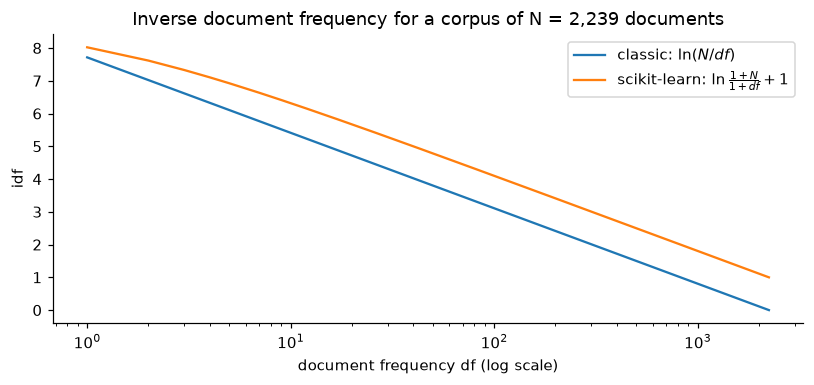

In [8]:
Ns = 2239   # the size of our newsgroups training set
dfs = np.arange(1, Ns + 1)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(dfs, np.log(Ns / dfs), label=r"classic: $\ln(N/df)$")
ax.plot(dfs, np.log((1 + Ns) / (1 + dfs)) + 1, label=r"scikit-learn: $\ln\frac{1+N}{1+df}+1$")
ax.set_xscale("log"); ax.set_xlabel("document frequency df (log scale)"); ax.set_ylabel("idf")
ax.set_title(f"Inverse document frequency for a corpus of N = {Ns:,} documents")
ax.legend(); plt.tight_layout(); plt.savefig(DOCS / "04_idf_curve.png", bbox_inches="tight"); plt.show()

On a log scale IDF is a straight line: every time a term becomes 10× more common, it loses the same
amount of weight ($\ln 10 \approx 2.3$).

## 4 · TF-IDF by hand
The TF-IDF weight is simply the product

$$\text{tf-idf}(t,d) = \mathrm{tf}(t,d) \times \mathrm{idf}(t)$$

scikit-learn then **L2-normalises** each document vector, $\mathbf{v} \leftarrow \mathbf{v}/\lVert\mathbf{v}\rVert_2$,
so that long and short documents are comparable (and so that the dot product of two rows is their cosine
similarity — see notebook 06). Here is the complete recipe in four NumPy lines:

In [9]:
def tfidf_by_hand(counts, smooth_idf=True, sublinear_tf=False, norm=True):
    n = counts.shape[0]
    tf = np.where(counts > 0, 1 + np.log(np.where(counts > 0, counts, 1)), 0) if sublinear_tf else counts
    df_ = (counts > 0).sum(axis=0)
    idf = np.log((1 + n) / (1 + df_)) + 1 if smooth_idf else np.log(n / df_) + 1
    W = tf * idf
    if norm:
        W = W / np.linalg.norm(W, axis=1, keepdims=True)
    return W, idf

W_hand, idf_hand = tfidf_by_hand(counts)
pd.DataFrame(W_hand, index=rows, columns=vocab).round(3)

,and,ball,cheered,crowd,delayed,landed,launch,orbit,pitcher,reached,rocket,the,threw,was
d0,0.302,0.000,0.00,0.00,0.000,0.383,0.000,0.383,0.000,0.302,0.604,0.400,0.000,0.000
d1,0.000,0.432,0.00,0.00,0.000,0.000,0.000,0.000,0.432,0.000,0.000,0.572,0.548,0.000
d2,0.000,0.000,0.00,0.00,0.507,0.000,0.507,0.000,0.000,0.000,0.400,0.264,0.000,0.507
d3,0.299,0.299,0.38,0.38,0.000,0.000,0.000,0.000,0.299,0.299,0.000,0.594,0.000,0.000


Look at `d0`: *the* and *rocket* both occur twice, but *rocket* appears in only two documents while *the*
appears in all four, so *rocket* gets the largest weight in the row (0.604) and *the* drops to 0.400. In `d2`,
where every word occurs once, the words found in a single document (*launch*, *was*, *delayed*) outweigh
*rocket*, and *the* gets the smallest weight.

### Cross-check against `TfidfVectorizer`
We pass `token_pattern=r"\S+"` so scikit-learn splits on whitespace exactly as we did (its default pattern
would drop one-letter tokens).

In [10]:
tv = TfidfVectorizer(token_pattern=r"\S+")
W_sk = tv.fit_transform(toy).toarray()
assert list(tv.get_feature_names_out()) == vocab
print("max |hand - sklearn| (weights):", np.abs(W_hand - W_sk).max())
print("max |hand - sklearn| (idf):    ", np.abs(idf_hand - tv.idf_).max())
assert np.allclose(W_hand, W_sk) and np.allclose(idf_hand, tv.idf_)
print("Our hand-made TF-IDF matches TfidfVectorizer.")

max |hand - sklearn| (weights): 0.0
max |hand - sklearn| (idf):     0.0
Our hand-made TF-IDF matches TfidfVectorizer.


In [11]:
for kw in [dict(smooth_idf=False), dict(sublinear_tf=True), dict(smooth_idf=False, sublinear_tf=True)]:
    W_h, _ = tfidf_by_hand(counts, **kw)
    W_s = TfidfVectorizer(token_pattern=r"\S+", **kw).fit_transform(toy).toarray()
    print(f"{str(kw):<45} identical: {np.allclose(W_h, W_s)}")

{'smooth_idf': False}                         identical: True
{'sublinear_tf': True}                        identical: True
{'smooth_idf': False, 'sublinear_tf': True}   identical: True


## 5 · TF-IDF on real newsgroup posts
Now the 20 Newsgroups training set (2,239 posts, 4 topics), tokenised with the `preprocess()` function
from notebook 02. We preprocess once and pass the token lists through an identity `analyzer`.

In [12]:
df = nlp_course.load_newsgroups()
train = df[df["subset"] == "train"].reset_index(drop=True)
tokenized = [nlp_course.preprocess(t) for t in train["text"]]
identity = lambda tokens: tokens

cv = CountVectorizer(analyzer=identity)
C_train = cv.fit_transform(tokenized)             # sparse raw counts
terms = cv.get_feature_names_out()
n_docs, n_terms = C_train.shape
print(f"{n_docs:,} documents x {n_terms:,} terms")

2,239 documents x 18,073 terms


### IDF of real words
We compute document frequency and IDF by hand on the sparse count matrix.

In [13]:
df_real = np.asarray((C_train > 0).sum(axis=0)).ravel()
idf_real = np.log((1 + n_docs) / (1 + df_real)) + 1
words = ["would", "one", "get", "space", "image", "nasa", "orbit", "baseball", "pitcher", "shuttle", "jpeg"]
idx = [cv.vocabulary_[w] for w in words]
pd.DataFrame({"df": df_real[idx], "% of docs": (100 * df_real[idx] / n_docs).round(1),
              "idf": idf_real[idx].round(3)}, index=words)

,df,% of docs,idf
would,615,27.5,2.291
one,567,25.3,2.372
get,612,27.3,2.296
space,240,10.7,3.229
image,144,6.4,3.737
nasa,111,5.0,3.996
orbit,97,4.3,4.129
baseball,94,4.2,4.160
pitcher,58,2.6,4.637
shuttle,65,2.9,4.525


In [14]:
j_min = idf_real.argmin()
print(f"lowest idf : {terms[j_min]!r} (df = {df_real[j_min]}, idf = {idf_real[j_min]:.3f})")
print(f"highest idf: {idf_real.max():.3f}, shared by the {(df_real == 1).sum():,} terms that occur in a single document")

lowest idf : 'would' (df = 615, idf = 2.291)
highest idf: 8.021, shared by the 9,060 terms that occur in a single document


The words that occur everywhere (*would*, *get*, *one*) get the lowest weights; topical words such as
*orbit*, *pitcher* or *jpeg* are rarer and get larger weights.

### Hand-made TF-IDF on the full corpus vs scikit-learn
The same recipe, written for a sparse matrix so it scales to the whole corpus.

In [15]:
from scipy import sparse
from sklearn.preprocessing import normalize

W_hand_real = normalize(C_train.astype(float) @ sparse.diags(idf_real), norm="l2")   # tf * idf, then L2

tv = TfidfVectorizer(analyzer=identity)
W_sk_real = tv.fit_transform(tokenized)
print("same vocabulary:", (tv.get_feature_names_out() == terms).all())
print("max |hand - sklearn|:", abs(W_hand_real - W_sk_real).max())
assert np.allclose(W_hand_real.toarray(), W_sk_real.toarray())

same vocabulary: True
max |hand - sklearn|: 3.3306690738754696e-15


### Counts vs TF-IDF for one document
Here is a real post from `sci.space`. Which words describe it best?

In [16]:
i = 150
print(train.loc[i, "category"])
print(train.loc[i, "text"][:600])

sci.space
The difficulties of a high Isp OTV include:
Long transfer times (radiation damage from VanAllen belts for both
 the spacecraft and OTV
Arcjets or Xenon thrusters require huge amounts of power so you have
to have either nuclear power source (messy, dangerous and source of
radiation damage) or BIG solar arrays (sensitive to radiation, or heavy)
that make attitude control and docking a big pain.

If you go solar, you have to replace the arrays every trip, with
current technology. Nuclear power sources are strongly restricted
by international treaty.

Refueling (even for very high Isp like xenon) 


In [17]:
row_counts = C_train[i].toarray().ravel()
row_tfidf = W_sk_real[i].toarray().ravel()
top_c = row_counts.argsort()[::-1][:10]
top_w = row_tfidf.argsort()[::-1][:10]
pd.DataFrame({"top by count": [f"{terms[j]} ({row_counts[j]:.0f})" for j in top_c],
              "top by TF-IDF": [f"{terms[j]} ({row_tfidf[j]:.3f})" for j in top_w]})

,top by count,top by TF-IDF
0,high (4),otv (0.311)
1,power (3),isp (0.283)
2,radiation (3),radiation (0.246)
3,otv (3),xenon (0.219)
4,require (3),refuel (0.208)
5,source (3),high (0.202)
6,isp (3),dock (0.189)
7,pain (2),pain (0.181)
8,dock (2),source (0.168)
9,array (2),require (0.163)


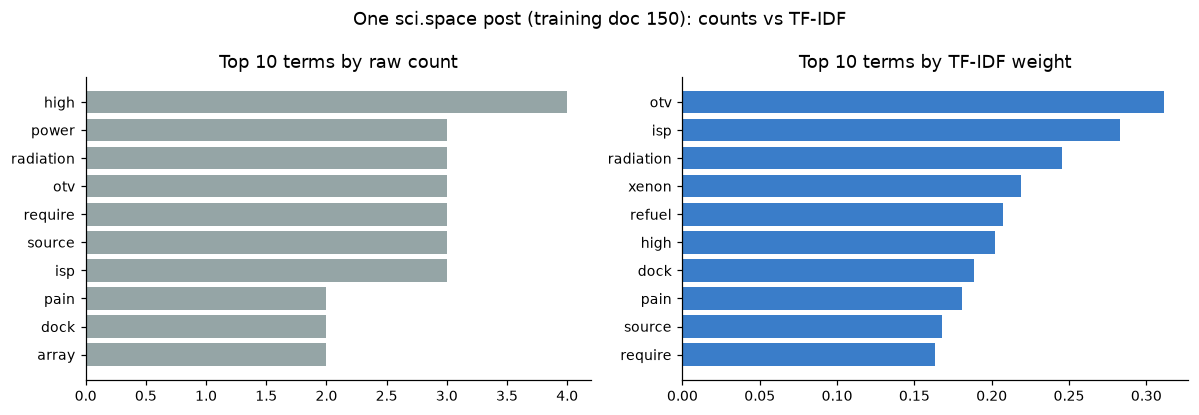

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, order, vals, title, color in [(axes[0], top_c, row_counts, "raw count", "#95a5a6"),
                                      (axes[1], top_w, row_tfidf, "TF-IDF weight", "#3a7dc9")]:
    ax.barh(terms[order][::-1], vals[order][::-1], color=color)
    ax.set_title(f"Top 10 terms by {title}"); ax.tick_params(labelsize=9)
fig.suptitle(f"One sci.space post (training doc {i}): counts vs TF-IDF")
plt.tight_layout(); plt.savefig(DOCS / "04_count_vs_tfidf_doc.png", bbox_inches="tight"); plt.show()

In [19]:
dropped = [terms[j] for j in top_c if j not in set(top_w)]
entered = [terms[j] for j in top_w if j not in set(top_c)]
print("left the top-10 with TF-IDF   :", [(t, int(df_real[cv.vocabulary_[t]])) for t in dropped], "(term, df)")
print("entered the top-10 with TF-IDF:", [(t, int(df_real[cv.vocabulary_[t]])) for t in entered], "(term, df)")
print("rank of 'high' by count:", list(terms[top_c]).index("high") + 1, "| by TF-IDF:", list(terms[top_w]).index("high") + 1)

left the top-10 with TF-IDF   : [('power', 125), ('array', 19)] (term, df)
entered the top-10 with TF-IDF: [('xenon', 1), ('refuel', 2)] (term, df)
rank of 'high' by count: 1 | by TF-IDF: 6


TF-IDF re-ranks the terms of the post. *power* (found in 125 posts) and *array* (19 posts) leave the top 10;
*xenon* (found only in this post) and *refuel* (2 posts) enter it. *high*, the most frequent word in the post, falls from 1st to 6th
because it is common in the whole corpus, while the specific acronyms *otv* and *isp* rise to the top.

### The most characteristic words of each topic
Let us average the TF-IDF vectors of all posts in a category and compare with the raw-count topic lists of
notebook 03.

In [20]:
top = {}
mean_by_cat = {}
for cat in sorted(train["category"].unique()):
    mask = (train["category"] == cat).to_numpy()
    mean_w = np.asarray(W_sk_real[mask].mean(axis=0)).ravel()
    mean_by_cat[cat] = mean_w
    top[cat] = list(terms[mean_w.argsort()[::-1][:12]])
pd.DataFrame(top)

,comp.graphics,rec.sport.baseball,sci.space,talk.politics.misc
0,file,game,space,people
1,graphic,year,would,government
2,image,team,launch,would
3,thank,player,nasa,say
4,use,run,get,tax
5,program,pitch,orbit,state
6,know,hit,think,make
7,look,baseball,like,think
8,anyone,think,one,get
9,would,get,moon,one


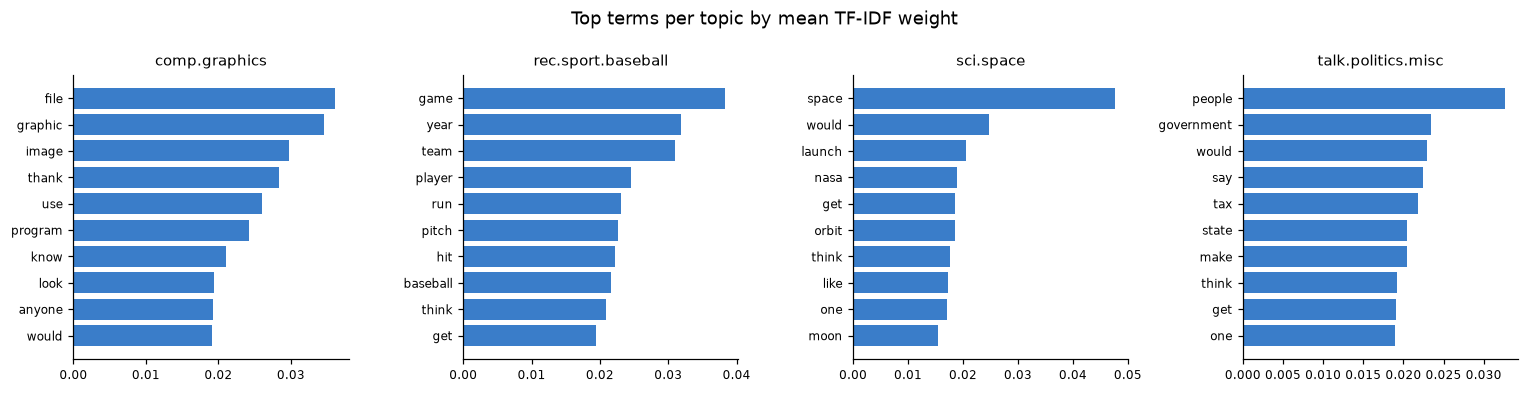

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (cat, mean_w) in zip(axes, mean_by_cat.items()):
    idx = mean_w.argsort()[::-1][:10][::-1]
    ax.barh(terms[idx], mean_w[idx], color="#3a7dc9")
    ax.set_title(cat, fontsize=10); ax.tick_params(labelsize=8)
fig.suptitle("Top terms per topic by mean TF-IDF weight")
plt.tight_layout(); plt.savefig(DOCS / "04_tfidf_top_words_per_category.png", bbox_inches="tight"); plt.show()

In [22]:
generic = ["would", "get", "one"]
for cat in top:
    print(f"{cat:<20} generic words in its TF-IDF top-12: {[w for w in generic if w in top[cat]]}")

comp.graphics        generic words in its TF-IDF top-12: ['would']
rec.sport.baseball   generic words in its TF-IDF top-12: ['get']
sci.space            generic words in its TF-IDF top-12: ['would', 'get', 'one']
talk.politics.misc   generic words in its TF-IDF top-12: ['would', 'get', 'one']


The picture improves but is not perfect. In `comp.graphics` and `rec.sport.baseball` most generic words
have left the top 12, while in `sci.space` and `talk.politics.misc` *would*, *get* and *one* are still there.
The reason: IDF only *dampens* a word that occurs in about a quarter of all posts (idf ≈ 2.3 versus ≈ 4–5 for
topical words), and averaging rewards words used in *many* posts of the topic. TF-IDF is a better weighting,
not a topic detector — learning which words *discriminate* between topics is the job of the classifiers in
notebook 10.

## 6 · Useful `TfidfVectorizer` options

| Option | Default | Effect |
|---|---|---|
| `sublinear_tf=True` | `False` | use $1+\ln f_{t,d}$ instead of raw counts |
| `smooth_idf` | `True` | add-one smoothing inside the IDF |
| `use_idf=False` | `True` | TF only (plus normalisation) |
| `norm` | `"l2"` | `"l1"`, `"l2"` or `None` |
| `min_df`, `max_df`, `max_features` | — | vocabulary control, as in `CountVectorizer` |
| `ngram_range` | `(1, 1)` | add bigrams, trigrams… (notebook 05) |

`TfidfVectorizer` is just `CountVectorizer` followed by `TfidfTransformer`:

In [23]:
from sklearn.feature_extraction.text import TfidfTransformer
W_two_step = TfidfTransformer().fit_transform(C_train)
print("CountVectorizer + TfidfTransformer == TfidfVectorizer:", np.allclose(W_two_step.toarray(), W_sk_real.toarray()))

CountVectorizer + TfidfTransformer == TfidfVectorizer: True


In [24]:
tv_sub = TfidfVectorizer(analyzer=identity, sublinear_tf=True)
W_sub = tv_sub.fit_transform(tokenized)
row_sub = W_sub[i].toarray().ravel()
pd.DataFrame({"term": terms[top_w], "count": row_counts[top_w].astype(int),
              "tf-idf": row_tfidf[top_w].round(3), "sublinear tf-idf": row_sub[top_w].round(3)})

,term,count,tf-idf,sublinear tf-idf
0,otv,3,0.311,0.256
1,isp,3,0.283,0.233
2,radiation,3,0.246,0.202
3,xenon,2,0.219,0.218
4,refuel,2,0.208,0.207
5,high,4,0.202,0.142
6,dock,2,0.189,0.188
7,pain,2,0.181,0.180
8,source,3,0.168,0.138
9,require,3,0.163,0.134


With `sublinear_tf=True`, a term repeated several times in the post loses part of its advantage over
terms that appear once, because $1+\ln f$ grows much more slowly than $f$.

### Fit on train, transform the test set
As always, the IDF statistics are learned on the training documents only. At `transform` time a test
document is weighted with the training IDF, and unseen words are dropped.

In [25]:
test = df[df["subset"] == "test"].reset_index(drop=True)
W_test = tv.transform([nlp_course.preprocess(t) for t in test["text"]])
print("test TF-IDF matrix:", W_test.shape)
norms = np.sqrt(np.asarray(W_test.multiply(W_test).sum(axis=1)).ravel())
print(f"rows with unit L2 norm: {np.isclose(norms, 1).sum():,}; empty rows (all words unseen): {(norms == 0).sum()}")

test TF-IDF matrix: (1490, 18073)
rows with unit L2 norm: 1,440; empty rows (all words unseen): 50


## 7 · Exercises

**Exercise 1.** By hand (no scikit-learn), compute the smoothed-IDF TF-IDF weight of *pitcher* in toy
document `d1` *before* normalisation, then after L2 normalisation, and compare with `W_sk`.

In [26]:
# your code here

<details>
<summary><b>Show solution</b></summary>

```python
j = vocab.index("pitcher")
f = docs[1].count("pitcher")
dft = sum("pitcher" in d for d in docs)
idf_p = np.log((1 + N) / (1 + dft)) + 1
raw = f * idf_p
row = np.array([docs[1].count(t) for t in vocab]) * (np.log((1 + N) / (1 + df_t)) + 1)
print(f"tf = {f}, df = {dft}, idf = {idf_p:.4f}, tf*idf = {raw:.4f}")
print(f"after L2 normalisation: {raw / np.linalg.norm(row):.4f}   sklearn: {W_sk[1, j]:.4f}")
```
</details>

In [27]:
j = vocab.index("pitcher")
f = docs[1].count("pitcher")
dft = sum("pitcher" in d for d in docs)
idf_p = np.log((1 + N) / (1 + dft)) + 1
raw = f * idf_p
row = np.array([docs[1].count(t) for t in vocab]) * (np.log((1 + N) / (1 + df_t)) + 1)
print(f"tf = {f}, df = {dft}, idf = {idf_p:.4f}, tf*idf = {raw:.4f}")
print(f"after L2 normalisation: {raw / np.linalg.norm(row):.4f}   sklearn: {W_sk[1, j]:.4f}")

tf = 1, df = 2, idf = 1.5108, tf*idf = 1.5108
after L2 normalisation: 0.4319   sklearn: 0.4319


**Exercise 2.** Compute TF-IDF for the **SMS Spam Collection** with
`TfidfVectorizer(stop_words="english", min_df=3)`. Which 10 terms have the highest *mean* TF-IDF among
spam messages, and which among ham messages?

In [28]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Spam is dominated by words like *free*, *txt*, *mobile*, *claim*; ham by conversational words.

```python
sms = nlp_course.load_sms()
tv_sms = TfidfVectorizer(stop_words="english", min_df=3)
W_sms = tv_sms.fit_transform(sms["text"])
vocab_sms = tv_sms.get_feature_names_out()
for label in ["spam", "ham"]:
    m = np.asarray(W_sms[(sms["label"] == label).to_numpy()].mean(axis=0)).ravel()
    print(f"{label:>4}:", list(vocab_sms[m.argsort()[::-1][:10]]))
```
</details>

In [29]:
sms = nlp_course.load_sms()
tv_sms = TfidfVectorizer(stop_words="english", min_df=3)
W_sms = tv_sms.fit_transform(sms["text"])
vocab_sms = tv_sms.get_feature_names_out()
for label in ["spam", "ham"]:
    m = np.asarray(W_sms[(sms["label"] == label).to_numpy()].mean(axis=0)).ravel()
    print(f"{label:>4}:", list(vocab_sms[m.argsort()[::-1][:10]]))

spam: ['free', 'txt', 'mobile', 'claim', 'text', 'stop', 'prize', 'reply', 'ur', 'www']
 ham: ['ok', 'll', 'come', 'gt', 'lt', 'just', 'good', 'got', 'like', 'know']


**Exercise 3.** In the newsgroups TF-IDF vocabulary, how many terms have the maximum IDF value (i.e.
occur in exactly one training document)? Refit with `min_df=2` and report the new vocabulary size and the
new maximum IDF.

In [30]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Words that occur in a single document get the highest weight but are often typos or names; `min_df` removes them.

```python
print("terms with the maximum idf:", (tv.idf_ == tv.idf_.max()).sum(), "of", len(tv.idf_))
tv2 = TfidfVectorizer(analyzer=identity, min_df=2).fit(tokenized)
print("vocabulary with min_df=2:", len(tv2.idf_), "| new max idf:", round(tv2.idf_.max(), 3))
```
</details>

In [31]:
print("terms with the maximum idf:", (tv.idf_ == tv.idf_.max()).sum(), "of", len(tv.idf_))
tv2 = TfidfVectorizer(analyzer=identity, min_df=2).fit(tokenized)
print("vocabulary with min_df=2:", len(tv2.idf_), "| new max idf:", round(tv2.idf_.max(), 3))

terms with the maximum idf: 9060 of 18073
vocabulary with min_df=2: 9013 | new max idf: 7.616


## Summary
- **TF** measures importance inside a document (raw, relative or log-scaled counts).
- **IDF** $=\ln(N/\mathrm{df})$ measures rarity across the corpus; scikit-learn uses the smoothed
  $\ln\frac{1+N}{1+\mathrm{df}}+1$.
- **TF-IDF** $=\mathrm{tf}\times\mathrm{idf}$, followed by L2 normalisation. Four lines of NumPy reproduce
  `TfidfVectorizer` exactly — on the toy corpus and on 2,239 real posts.
- TF-IDF demotes corpus-wide words (*would*, *get*, *one*) and promotes distinctive ones, giving cleaner
  document signatures than raw counts — though it dampens common words rather than removing them.

**Next:** [05 · N-grams](05_ngrams.ipynb) — bringing back some word order.